# Manipulation de la librairie networkx

## Construction de réseaux d'interactions à partir de données MITAB.

Le format (MITAB) stocke des paires de protéines en interaction. Dans ce format, chaque colonne porte une information spécifique.
Une description du format est disponible [ici](https://psicquic.github.io/MITAB27Format.html).
Les données d'interactions impliquant les protéines surreprésentées de l'expérience ont été obtenues depuis la base de données [Intact](https://www.ebi.ac.uk/intact/home).
Ces données sont mises à votre disposition dans le fichier `data/proteins.mitab`.

Vous extrairez du fichier les paires d'identifiants uniprot des protéines en interaction.

Ces paires de protéines constituent un réseau d'interaction protéine-protéine que vous allez dessiner à l'aide de la libraire [networkx](https://networkx.org/documentation/stable/reference).
Le code suivant vous est fourni à titre d'exemple.

```python
%matplotlib inline
import matplotlib.pyplot as plt
import networkx as nx
G = nx.Graph()

fig, ax = plt.subplots(figsize=(8, 8))

G.add_edge('a', 'b')
G.add_edge('e', 'b')
G.add_edge('e', 'a')
pos = nx.spring_layout(G)
nx.draw(G, pos, with_labels=True, node_color=['blue','blue','red'] , node_size=2000)
```


Les positions des noeuds sont paramétrables au travers de l'objet [layout](https://networkx.org/documentation/stable/reference/generated/networkx.drawing.layout.spring_layout.html). Une fois une première représentation du réseau obtenue, affinez celle-ci afin de:

* Écrire les identifiants uniprot dans les noeuds du réseau.
* Faire du diamètre des noeuds une fonction du nombre de partenaires protéiques.
* Faire de la largeur des arêtes une fonction du nombre d'experiences (lignes MITAB) detectant cette interaction
* Colorier les arêtes soutenues par au moins une interaction de type physique entre proteines.
* Utiliser une color map quantitative et divergente pour colorier les arêtes en fonction du nombre d'experiences (lignes MITAB) detectant cette interaction

###### TIPS
* Numpy permet d'interpoler de manière linéaire des valeurs à partir de deux couples min/max: i) données experimentales, ii) valeurs "graphiques".
```python
import numpy as np
xp = [0, 10] # Intervalle du domaine des valeurs observées min=0, max = 10
fp = [0, 100] # Intervalle du codomaine des valeurs à représenter, ex: "node_size" entre 0 (invis) et 100 (très gros)
np.interp(5, xp, fp) # affichera 50
```

## Croisement des données d'interaction et de protéomique

En utilisant les données d'abondance du fichier `TCL_wt1.tsv`, essayez de modifier le rendu du réseau pour:
* Colorier dans une couleur spécifique uniquement les protéines surabondantes dans l'expérience.
* Colorier en gris les noeuds des protéines non mesurées dans l'experience.
* Représenter l'abondance des protéines par:
  - Une échelle de couleur continue
  - Le diamètre des noeuds
* Representer dans une forme particulière les noeuds porteur d'un terme GO avec une bonne p-valeur

### Ajout des fonctions biologique

En utilisant les résultats de l'analyse ORA des TPs précédents:
* Colorier dans une même couleurs les noeuds des protéines impliquées dans la fonction biologique (terme(s) GO) de votre choix
* Construisez une figure contenant deux réseaux de même disposition représentant chacune les protéines impliquées dans une fonction biologique spécifique.

#### Controles Interactifs du réseau
En suivant le modèle de widgets décrits dans le [TP4](./TP4.ipynb), il est possible de rendre "interactif" le réseau d'exemple précédent. Dans l'exemple ci-dessous les couleurs des noms sont modifiées à la volée. Vous pouvez y voir que l'objet `pos`, qui stocke la position des noeuds et des arêtes, est calculé une fois et réutilisé à chaque mise à jour du réseau. Cela permet de preserver la forme du réseau.

```python
%matplotlib ipympl
import networkx as nx
from ipywidgets import interact, Dropdown
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import display, clear_output

G = nx.Graph()

G.add_edge('a', 'b')
G.add_edge('e', 'b')
G.add_edge('e', 'a')

pos = nx.spring_layout(G)
fig, ax = plt.subplots(figsize=(10, 10)) 
    

def update_network(scalar_color):
    color_list = [ scalar_color for n in G.nodes ]
    _ = nx.draw(G, ax=ax, pos=pos, node_color=color_list)
    _ = display(fig)
    clear_output()
_ = interact(update_network, scalar_color = [("Red color", "red"), ("Blue color", "blue")])
```

A l'aide de ce modèle, coloriez dynamiquement et séparement les protéines appartenant aux classes GO "enrichies" dans l'experience.
Referez vous au TP2 pour lister toutes les protéines portant un terme GO particulier.

In [9]:
from dataclasses import dataclass
@dataclass
class MitabDatum:
    idA:str
    idB:str
    aliasA:list[str]
    aliasB:list[str]
    detection_methods:list[str]
    interaction_type:str
    pmid:str

def mitab_parser(f_path)->list[MitabDatum]:
    mitab_data:list[MitabDatum] = []
    with open(f_path) as fp:
        for l in fp:
            _ = l.rstrip().split("\t")
            mitab_data.append(
                MitabDatum(_[0], _[1], _[2].split("|"), _[3].split("|"),  _[6].split("|"),  _[11],  _[8])
            )   
    return mitab_data
    
mitab_data = mitab_parser("../data/proteins.mitab")
mitab_data[1]

MitabDatum(idA='uniprotkb:P0ACF8', idB='uniprotkb:P0AFG8', aliasA=['intact:EBI-544934', 'uniprotkb:P08936', 'ensemblbacteria:AAC74319', 'ensemblbacteria:BAA36117', 'uniprotkb:Q47267'], aliasB=['intact:EBI-542683', 'uniprotkb:P06958', 'uniprotkb:P78049', 'uniprotkb:Q53382', 'ensemblbacteria:AAC73225', 'ensemblbacteria:BAB96684'], detection_methods=['psi-mi:"MI:0676"(tandem affinity purification)'], interaction_type='psi-mi:"MI:0914"(association)', pmid='pubmed:15690043|mint:MINT-5217509|imex:IM-21967|doi:10.1038/nature03239')

In [13]:
from __future__ import annotations

def create_point():
    return Point() 
    
class Point:

    unit = "centimeter"
    
    @classmethod
    def create_point(cls)->Point:
        return Point(199, 200, cls.unit)
                     
    def __init__(self, x, y, unit):
        self.x = x
        self.y = y
        self.unit = unit
        
    @classmethod
    def change_unit(cls, new_unit):
        cls.unit = new_unit

Point.create_point()

[2, 1, 1]


EdgeDataView([('a', 'b', {'xp_data': ['cookie', 'lemon']}), ('a', 'e', {'xp_data': ['cherry']}), ('b', 'e', {'xp_data': ['milk']})])

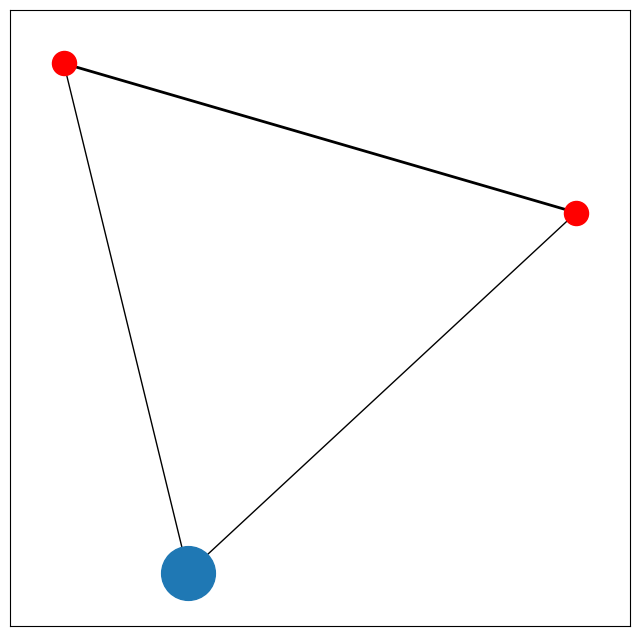

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import networkx as nx
# mettre a jour le dictionnaire de données de chaque arête
def my_add_edge(G,i, j, data):
    if not G.has_edge(i,j):
        G.add_edge(i,j, xp_data = [])
    G[i][j]["xp_data"].append(data)
    
G = nx.Graph()
fig, ax = plt.subplots(figsize=(8, 8))

my_add_edge(G, 'a', 'b', "cookie")
my_add_edge(G,'e', 'b', "milk")
my_add_edge(G,'e', 'a', "cherry")
my_add_edge(G,'a', 'b', "lemon")
pos = nx.spring_layout(G)
### dessin "simple"
# nx.draw(G, pos, with_labels=True, node_color=['blue','blue','red'] , node_size=2000)
### dessin avancé
## dessiner separement arête et noeuds
e_width = [ len(data["xp_data"]) for a,b,data in G.edges(data=True) ]
print(e_width)
nx.draw_networkx_edges(G, pos, width = e_width * 10 )

nx.draw_networkx_nodes(G, pos, ["a", "b"], node_color = "red")
# Appliquer plusieurs styles au même noeud
nx.draw_networkx_nodes(G, pos, ["e"], node_color = "blue")
nx.draw_networkx_nodes(G, pos, ["e"], node_size = 1500)
G.edges(data=True)